# 04 — Switched-Mode Buck Converter Benchmark (M5)

This notebook runs the **measured** buck-converter testbench in
`simulation/testbenches/buck_converter.py` around an explicitly selected
emitted device model. Every number below is extracted from a real transient
simulation over the settled post-startup window defined in
`config/converter.yaml`; nothing is a fabricated speedup or an analytic
estimate.

- **Single selected model:** `VENDOR` and `TIER_KEY` are the only selectors;
  the operating point, gate drive, freewheel leg and simulation window all
  come from the validated YAML config.
- **Golden vs tier:** the comparison cell runs the vendor golden model and the
  selected tier under the same netlist/conditions and plots their waveforms.
- **N/A is explicit:** a missing trace, aborted run or unavailable library
  reports `N/A` with the bench guard reason. Nothing is zero-filled or imputed.

## Tier notes (honest scope)

| Key | Meaning | Known limitation |
|---|---|---|
| `tier2` | Piecewise-linear / charge-table macromodel | switching detail limited by the fitted table |
| `tier3` | Tier-3 charge-based model, variant `v1` | the full v1 netlist can exceed the configured timeout and return N/A |
| `tier3_simplis` | Tier-3 SIMPLIS-oriented variant | same charge-model scope |
| `urom` | unified one-ROM candidate (`tier=3`, variant `urom`) | candidate model, not a validated release |
| `tier4` | ideal switch + offline loss LUT | **no active electrical loss element** in the emitted switch; converter efficiency/loss is therefore not physically attributed and comes back N/A |

The Tier-4 row is runnable and useful for waveform/timing comparison, but its
efficiency is N/A by design. It is not evidence of a measured converter
efficiency. Tier-3 v1 may be N/A/timeout; this notebook never retries with a
different operating point to manufacture a result.


## 1 · Configuration and selection

Change `VENDOR` / `TIER_KEY` and re-run; the config is loaded through
`load_converter_config`, which fails closed on a malformed or incomplete
`config/converter.yaml`. No bench parameter is hardcoded here.


In [1]:
%matplotlib inline
# Explicit, reproducible selection: change only these two variables.
import os
import sys
import time
from pathlib import Path

os.environ.setdefault("MPLBACKEND", "Agg")
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

VENDOR = "epc2216"
TIER_KEY = "tier2"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from common.plotting import (
    figure_path,
    plot_converter_benchmark,
    plot_converter_comparison,
)
from simulation.testbenches.buck_converter import (
    load_converter_config,
    run_converter_benchmark,
    run_converter_comparison,
)

CONFIG_PATH = REPO_ROOT / "config" / "converter.yaml"
config = load_converter_config(CONFIG_PATH)
tiers = config["model_selection"]["tiers"]
supported_tiers = tuple(tiers)
if TIER_KEY not in tiers:
    raise ValueError(f"TIER_KEY={TIER_KEY!r} is not one of {supported_tiers}")
if VENDOR not in config["vendors"]:
    raise ValueError(
        f"VENDOR={VENDOR!r} has no entry in config/converter.yaml; "
        f"configured: {tuple(config['vendors'])}")

entry = tiers[TIER_KEY]
cond = config["conditions"]
sim = cond["simulation"]
print(f"Config          : {CONFIG_PATH.relative_to(REPO_ROOT)}")
print(f"Vendor          : {VENDOR}")
print(f"Selected tier   : {TIER_KEY} "
      f"(tier={entry['tier']}, variant={entry['variant']!r})")
print(f"Supported tiers : {', '.join(supported_tiers)}")
print(f"Bus / target    : {cond['vbus_v']:g} V / {cond['vout_target_v']:g} V")
print(f"f_sw / duty     : {cond['f_sw_hz'] / 1e3:g} kHz / {cond['duty']:g}")
print(f"Load / L / Cout : {cond['r_load_ohm']:g} ohm / "
      f"{cond['l_h'] * 1e6:g} uH / {cond['c_out_f'] * 1e6:g} uF")
print(f"Cycles          : {sim['cycles']} "
      f"(settling {sim['settling_cycles']}), timeout {sim['timeout_s']:g} s")

Config          : config\converter.yaml
Vendor          : epc2216
Selected tier   : tier2 (tier=2, variant='v1')
Supported tiers : tier2, tier3, tier3_simplis, urom, tier4
Bus / target    : 12 V / 5 V
f_sw / duty     : 200 kHz / 0.45
Load / L / Cout : 5 ohm / 22 uH / 47 uF
Cycles          : 300 (settling 240), timeout 180 s


## 2 · One selected-model benchmark

`run_converter_benchmark` measures `Vout`, `I(Rload)` and `I(Vbus)` over the
settled window and computes efficiency only from those measured means. The
table preserves `N/A` for every field the bench could not measure.


In [2]:
def fmt(value, spec=".4f", unit="", scale=1.0):
    """Format a measured value; None/non-finite is always the literal N/A."""
    if value is None:
        return "N/A"
    try:
        number = float(value)
    except (TypeError, ValueError):
        return str(value)
    if not np.isfinite(number):
        return "N/A"
    return f"{number * scale:{spec}}{unit}"


started = time.perf_counter()
result = run_converter_benchmark(VENDOR, TIER_KEY, config=config)
elapsed = time.perf_counter() - started

guard = result.get("guard") or {}
speed = result.get("speed") or {}
library = result.get("library") or {}
status = result.get("status")

rows = [
    ("Status", status or "N/A"),
    ("Settled", result.get("settled") if result.get("settled") is not None else "N/A"),
    ("Vout", fmt(result.get("vout_v"), ".4f", " V")),
    ("Vout error", fmt(result.get("vout_error_pct"), ".2f", " %")),
    ("Iout", fmt(result.get("iout_a"), ".4f", " A")),
    ("Efficiency", fmt(result.get("efficiency"), ".2f", " %", 100.0)),
    ("Pin", fmt(result.get("pin_w"), ".4f", " W")),
    ("Pout", fmt(result.get("pout_w"), ".4f", " W")),
    ("Wall clock", fmt(speed.get("wall_clock_s"), ".3f", " s")),
    ("Iterations", fmt(speed.get("iterations"), ".0f")),
    ("Trace points", fmt(speed.get("trace_points"), ".0f")),
    ("Guard completed", guard.get("completed", "N/A")),
    ("Guard reason", result.get("reason") or guard.get("reason") or "N/A"),
]
display(pd.DataFrame(rows, columns=["Measurement", "Value"]).set_index("Measurement"))

print(f"Measured run wall clock (cell) : {elapsed:.3f} s")
print(f"Library                        : "
      f"{library.get('path') or 'N/A'}")
print(f"Netlist sha256                 : {result.get('netlist_sha256') or 'N/A'}")
if status == "measured":
    print("Measured status: complete and settled; efficiency above is measured.")
else:
    print(f"Measured status: {status!r}; N/A values are preserved, not imputed.")

,Value
Measurement,
Status,measured
Settled,True
Vout,5.3053 V
Vout error,6.11 %
Iout,1.0611 A
Efficiency,96.91 %
Pin,5.8085 W
Pout,5.6292 W
Wall clock,10.400 s


Measured run wall clock (cell) : 10.416 s
Library                        : C:\Users\GNKRISHNAN\Documents\GitHub\PieceSpice\reports\models\epc2216_PIECESPICE_T2.lib
Netlist sha256                 : b158e487b503a3f0724259f0dea4cb06408c879a3cb895b2509b45d1b6004c43
Measured status: complete and settled; efficiency above is measured.


## 3 · Selected-model plot

The plotting helper owns the house style (300 dpi, engineering units, EAST
legends) and the fixed `figures/converter/` path. The notebook only passes the
measured result through and displays the returned figure.


Saved selected-model plot: figures\converter\epc2216_tier2_buck.png
File size                : 399.3 KiB


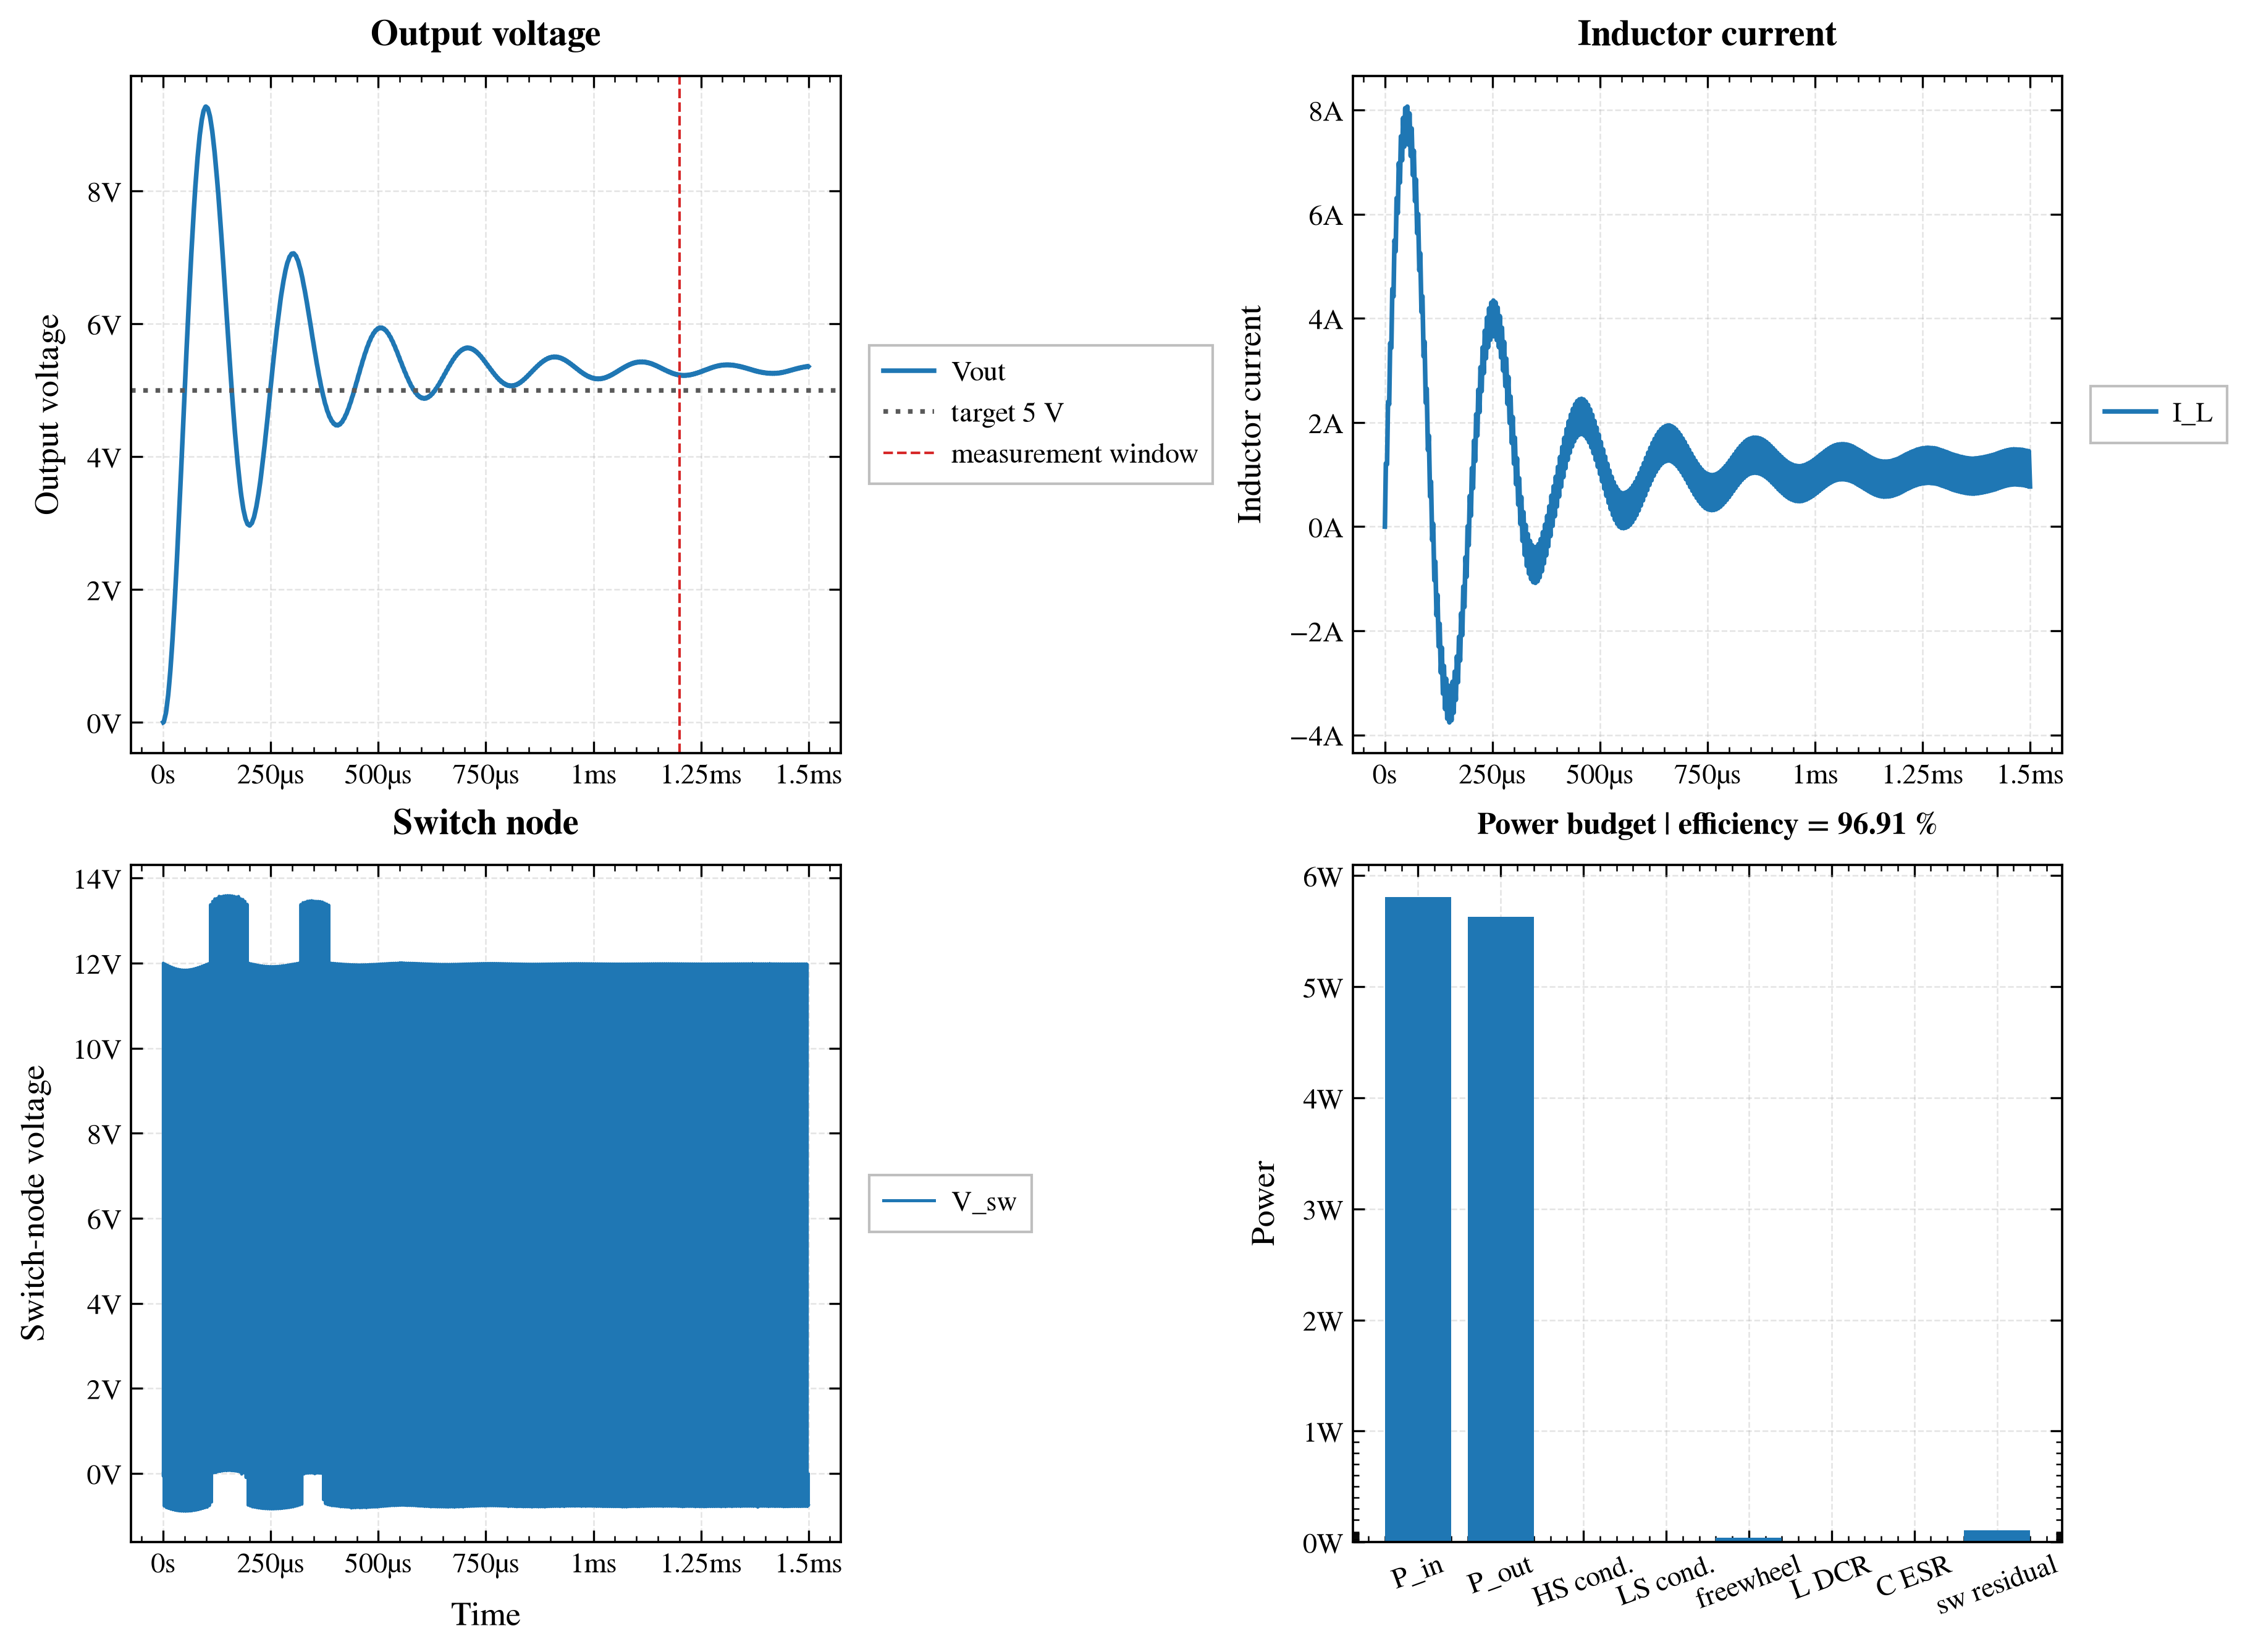

In [3]:
traces = result.get("traces") or {}
if "time" not in traces:
    print(f"Plot N/A: status={result.get('status')!r}, "
          f"reason={result.get('reason') or 'no measured traces'}")
else:
    fig, axes = plot_converter_benchmark(result, show=False)
    saved_plot = figure_path("converter", f"{VENDOR}_{TIER_KEY}_buck.png")
    print(f"Saved selected-model plot: {saved_plot.relative_to(REPO_ROOT)}")
    print(f"File size                : {saved_plot.stat().st_size / 1024:.1f} KiB")
    display(fig)
    plt.close(fig)

## 4 · Golden vs selected tier

`run_converter_comparison` runs the vendor golden model and the selected tier
through the same buck netlist and conditions, then returns both measured
records plus a comparison payload. The table below reports each arm
separately; `N/A` is intrinsic where an arm cannot produce a number (for
example Tier-4 efficiency).


In [4]:
def arm_row(label, arm):
    arm = arm or {}
    arm_guard = arm.get("guard") or {}
    return {
        "Arm": label,
        "Status": arm.get("status") or "N/A",
        "Vout (V)": fmt(arm.get("vout_v"), ".4f"),
        "Efficiency": fmt(arm.get("efficiency"), ".2f", " %", 100.0),
        "Guard completed": arm_guard.get("completed", "N/A"),
        "Guard reason": arm.get("reason") or arm_guard.get("reason") or "N/A",
    }


comparison_started = time.perf_counter()
comparison = run_converter_comparison(VENDOR, TIER_KEY, config=config)
comparison_elapsed = time.perf_counter() - comparison_started

golden = comparison.get("golden") or {}
tier = comparison.get("tier") or {}
compare = comparison.get("comparison") or {}

table = pd.DataFrame([
    arm_row("golden (vendor)", golden),
    arm_row(f"tier ({TIER_KEY})", tier),
]).set_index("Arm")
display(table)
print(f"Comparison wall clock (cell): {comparison_elapsed:.3f} s")

signals = dict(compare.get("signals") or {})
signals["efficiency"] = compare.get("efficiency") or {}
labels = {
    "vout_v": "vout (V)",
    "i_l_mean_a": "i_l mean (A)",
    "i_cap_mean_a": "i_cap mean (A)",
    "efficiency": "efficiency (%)",
}
rows = []
for name, entry in signals.items():
    scale = 100.0 if name == "efficiency" else 1.0
    spec = ".2f" if name == "efficiency" else ".4f"
    rows.append({
        "Signal": labels.get(name, name),
        "Golden": fmt(entry.get("golden"), spec, scale=scale),
        "Tier": fmt(entry.get("tier"), spec, scale=scale),
        "Abs error": fmt(entry.get("abs_error"), spec, scale=scale),
        "Rel error (%)": fmt(entry.get("rel_error_pct"), ".2f"),
        "Status": entry.get("status") or "N/A",
    })
if rows:
    display(pd.DataFrame(rows).set_index("Signal"))
print("Comparison status:", compare.get("status") or "N/A")
print("Comparison reason:", compare.get("reason") or "N/A")

,Status,Vout (V),Efficiency,Guard completed,Guard reason
Arm,,,,,
golden (vendor),measured,5.3077,97.55 %,True,N/A
tier (tier2),measured,5.3053,96.91 %,True,N/A


Comparison wall clock (cell): 31.384 s


,Golden,Tier,Abs error,Rel error (%),Status
Signal,,,,,
vout (V),5.3077,5.3053,-0.0024,-0.04,compared
i_l mean (A),1.0761,1.0815,0.0054,0.50,compared
i_cap mean (A),0.0146,0.0204,0.0058,39.89,compared
efficiency (%),97.55,96.91,-0.63,-0.65,compared


Comparison status: compared
Comparison reason: N/A


### Golden-vs-tier waveform plot

One 1×3 panel set: output voltage, inductor current and capacitor current,
golden against the selected tier. Same style/path policy as the single run.


Saved comparison plot: figures\converter\epc2216_tier2_buck_compare.png
File size            : 337.3 KiB


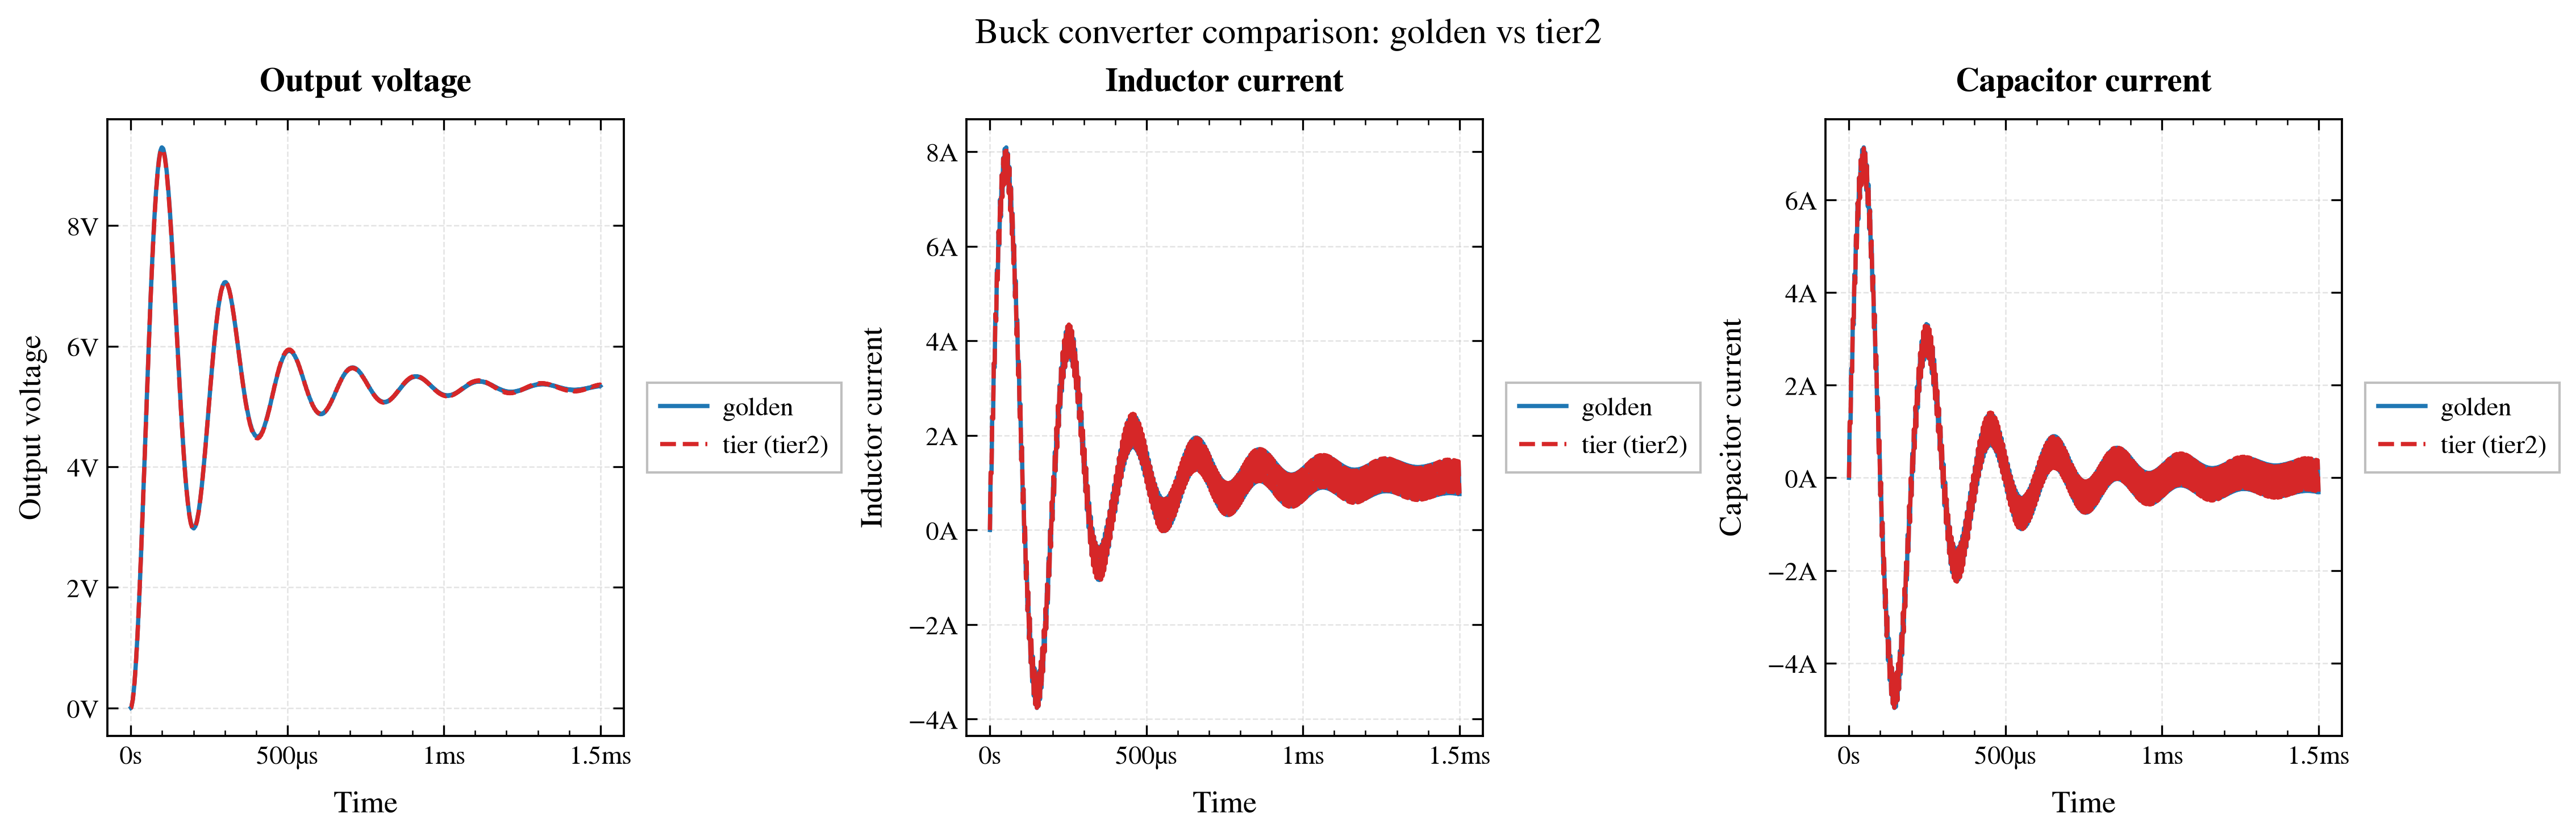

In [5]:
arms = (comparison.get("golden") or {}, comparison.get("tier") or {})
missing = [i for i, arm in enumerate(arms)
           if "time" not in (arm.get("traces") or {})]
if missing:
    labels = ["golden", f"tier ({TIER_KEY})"]
    print("Comparison plot N/A: no measured traces for "
          + ", ".join(labels[i] for i in missing))
else:
    fig, axes = plot_converter_comparison(comparison)
    saved_compare = figure_path(
        "converter", f"{VENDOR}_{TIER_KEY}_buck_compare.png")
    print(f"Saved comparison plot: {saved_compare.relative_to(REPO_ROOT)}")
    print(f"File size            : {saved_compare.stat().st_size / 1024:.1f} KiB")
    display(fig)
    plt.close(fig)

## 5 · Recorded references (optional, not re-run)

Only same-bench records may be compared numerically. The notebook does not
re-run every tier; when no recorded converter-bench Tier-2/Tier-4 JSON is
present, no cross-bench number is invented. The Tier-4 record's efficiency
status is displayed only as scope evidence.


In [6]:
recorded_path = (REPO_ROOT / "reports" / "comparison" / VENDOR /
                 "tier4_validation.json")
if recorded_path.is_file():
    import json
    recorded = json.loads(recorded_path.read_text(encoding="utf-8"))
    gate = recorded.get("efficiency_gate") or {}
    reference = pd.DataFrame([
        {
            "Source": "recorded Tier-4 (DPT/LUT, not this converter bench)",
            "Efficiency": "N/A" if gate.get("efficiency") is None
                          else fmt(gate.get("efficiency"), ".2f", " %", 100.0),
            "Efficiency status": gate.get("status") or "N/A",
        }
    ])
    display(reference.set_index("Source"))
    print("Recorded Tier-4 efficiency is N/A by design: the emitted switch "
          "has no active electrical loss element.")
else:
    print(f"No recorded Tier-4 reference at "
          f"{recorded_path.relative_to(REPO_ROOT)}; nothing to compare.")
print("No recorded same-bench converter metrics for other tiers were found; "
      "the measured arms above are the only converter numbers reported.")

,Efficiency,Efficiency status
Source,,
"recorded Tier-4 (DPT/LUT, not this converter bench)",N/A,output_power_required


Recorded Tier-4 efficiency is N/A by design: the emitted switch has no active electrical loss element.
No recorded same-bench converter metrics for other tiers were found; the measured arms above are the only converter numbers reported.
